<a href="https://colab.research.google.com/github/notebooklm1958-tech/-Analyse-rapide-d-une-action-bas-e-/blob/main/analyse_rapide_action_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analyse rapide d'une action basée sur 4 indicateurs clés

Ce notebook récupère des informations depuis Yahoo Finance avec `yfinance` et présente : la capitalisation boursière, le PER, le rendement du dividende et la position du cours dans sa fourchette des 52 dernières semaines.

> Les données peuvent être retardées, absentes ou révisées. Cette analyse est indicative et ne constitue pas un conseil financier. Le PER et le rendement du dividende doivent être interprétés selon le secteur et la situation de l'entreprise.

## 1. Installer la dépendance (si nécessaire)

Exécute cette cellule une seule fois si `yfinance` n'est pas déjà installé dans ton environnement.

In [2]:
!pip install -q yfinance pandas

## 2. Choisir l'action

Modifie `SYMBOL` ci-dessous. Exemples : `AAPL` (Apple), `MSFT` (Microsoft), `MC.PA` (LVMH à Paris), `AIR.PA` (Airbus à Paris). Le suffixe dépend de la place boursière.

In [3]:
import math
import pandas as pd
import yfinance as yf

# Demande à l'utilisateur de saisir le symbole
SYMBOL = input("Entrez le symbole Yahoo Finance (ex: AAPL, MSFT, MC.PA) : ").strip().upper()

ticker = yf.Ticker(SYMBOL)
info = ticker.get_info()

if not info:
    raise ValueError(f"Aucune information trouvée pour {SYMBOL!r}. Vérifie le symbole Yahoo Finance.")

nom = info.get("shortName") or info.get("longName") or SYMBOL
devise = info.get("currency", "")
print(f"\nSociété : {nom} ({SYMBOL})")
print(f"Devise des cours/valeurs : {devise or 'non précisée'}")

Entrez le symbole Yahoo Finance (ex: AAPL, MSFT, MC.PA) : AAPL

Société : Apple Inc. (AAPL)
Devise des cours/valeurs : USD


## 3. Récupérer et afficher les quatre indicateurs

Le PER affiché en premier est le PER historique (*trailing P/E*). Si Yahoo Finance ne le fournit pas, le notebook utilise le PER prévisionnel (*forward P/E*) et le précise. Pour le dividende, Yahoo Finance renvoie généralement un ratio décimal, converti ici en pourcentage.

In [4]:
def nombre(valeur):
    """Convertit une valeur en nombre exploitable, sinon renvoie None."""
    try:
        resultat = float(valeur)
        return resultat if math.isfinite(resultat) else None
    except (TypeError, ValueError):
        return None

def format_montant(valeur, devise=devise):
    if valeur is None:
        return "Indisponible"
    return f"{valeur:,.2f} {devise}".strip()

# 1) Capitalisation boursière
capitalisation = nombre(info.get("marketCap"))

# 2) PER : privilégier le PER historique, sinon afficher le PER prévisionnel
per_historique = nombre(info.get("trailingPE"))

per_previsionnel = nombre(info.get("forwardPE"))
if per_historique is not None:
    per = per_historique
    type_per = "historique"
else:
    per = per_previsionnel
    type_per = "prévisionnel (si disponible)"

# 3) Rendement du dividende. Certains résultats Yahoo sont exprimés en décimal.
rendement = nombre(info.get("dividendYield"))
if rendement is None:
    rendement_pct = None
else:
    rendement_pct = rendement * 100 if abs(rendement) <= 1 else rendement

# 4) Cours actuel et bornes 52 semaines
cours = (nombre(info.get("currentPrice")) or
         nombre(info.get("regularMarketPrice")) or
         nombre(info.get("previousClose")))
plus_bas = nombre(info.get("fiftyTwoWeekLow"))
plus_haut = nombre(info.get("fiftyTwoWeekHigh"))

if cours is None or plus_bas is None or plus_haut is None:
    historique = ticker.history(period="1y", auto_adjust=False)
    if not historique.empty:
        if cours is None:
            cours = nombre(historique["Close"].dropna().iloc[-1])
        if plus_bas is None:
            plus_bas = nombre(historique["Low"].min())
        if plus_haut is None:
            plus_haut = nombre(historique["High"].max())

# 5) Nouveaux indicateurs : Ratio des dépenses (Net) et Volumes
ratio_depenses = nombre(info.get("netExpenseRatio"))
if ratio_depenses is not None:
    # Conversion en pourcentage si nécessaire
    ratio_depenses_pct = ratio_depenses * 100 if ratio_depenses <= 1 else ratio_depenses
else:
    ratio_depenses_pct = None

volume_actuel = nombre(info.get("volume")) or nombre(info.get("regularMarketVolume"))
volume_moyen = nombre(info.get("averageVolume")) or nombre(info.get("averageVolume10Days"))

# Affichage des résultats
print(f"1. Capitalisation boursière : {format_montant(capitalisation)}")
if per is None:
    print("2. PER : Indisponible (par exemple, bénéfices négatifs, donnée non fournie ou ETF/Fonds)")
else:
    print(f"2. PER {type_per} : {per:.2f}")
if rendement_pct is None:
    print("3. Rendement du dividende : Indisponible ou aucun dividende déclaré")
else:
    print(f"3. Rendement du dividende : {rendement_pct:.2f} %")
if cours is not None and plus_bas is not None and plus_haut is not None:
    print(f"4. Cours actuel : {format_montant(cours)}")
    print(f"   Fourchette 52 semaines : {format_montant(plus_bas)} – {format_montant(plus_haut)}")
else:
    print("4. Fourchette 52 semaines : Indisponible")

if ratio_depenses_pct is not None:
    print(f"5. Ratio des dépenses (net) : {ratio_depenses_pct:.2f} % (Spécifique aux ETF/Fonds)")
else:
    print("5. Ratio des dépenses (net) : Non applicable ou non fourni (généralement réservé aux ETF/Fonds)")

if volume_actuel is not None:
    print(f"6. Volume actuel : {volume_actuel:,.0f}")
    if volume_moyen is not None:
        print(f"   Volume moyen : {volume_moyen:,.0f}")
else:
    print("6. Volume : Indisponible")

1. Capitalisation boursière : 5,092,055,449,600.00 USD
2. PER historique : 40.01
3. Rendement du dividende : 31.00 %
4. Cours actuel : 348.91 USD
   Fourchette 52 semaines : 243.42 USD – 351.73 USD
5. Ratio des dépenses (net) : Non applicable ou non fourni (généralement réservé aux ETF/Fonds)
6. Volume actuel : 40,889,228
   Volume moyen : 43,379,289


## 4. Lecture rapide

Les commentaires suivants sont descriptifs, pas des signaux d'achat ou de vente. Un PER élevé peut refléter des anticipations de croissance, tandis qu'un PER faible peut aussi signaler des difficultés. Un rendement élevé n'est pas nécessairement durable.

In [5]:
print(f"Synthèse indicative — {nom} ({SYMBOL.upper()})")
print("-" * 55)

if capitalisation is None:
    print("• Capitalisation : donnée indisponible.")
else:
    print(f"• Capitalisation : {format_montant(capitalisation)} ; elle donne un ordre de grandeur de la taille de l'entreprise.")

if per is None:
    print("• PER : indisponible ; il peut notamment ne pas être pertinent si les bénéfices sont négatifs ou s'il s'agit d'un fonds.")
elif per < 0:
    print(f"• PER : {per:.2f} ; valeur négative, à interpréter avec prudence (bénéfices négatifs ou données particulières).")
else:
    print(f"• PER {type_per} : {per:.2f} ; à comparer aux entreprises du même secteur et à la croissance attendue.")

if rendement_pct is None:
    print("• Dividende : aucun rendement disponible ; l'entreprise peut ne pas verser de dividende.")
else:
    print(f"• Rendement : {rendement_pct:.2f} % ; ce rendement passé/indiqué ne garantit pas les versements futurs.")

if cours is not None and plus_bas is not None and plus_haut is not None and plus_haut > plus_bas:
    position = (cours - plus_bas) / (plus_haut - plus_bas) * 100
    position = max(0, min(100, position))
    print(f"• Fourchette 52 semaines : cours à {position:.1f} % de l'intervalle entre le plus bas et le plus haut.")
    print("  Une position proche du haut/bas ne permet pas, à elle seule, de prévoir la direction future du cours.")
elif cours is not None:
    print(f"• Cours : {format_montant(cours)} ; bornes 52 semaines indisponibles ou non valides.")
else:
    print("• Fourchette 52 semaines : données insuffisantes pour calculer la position du cours.")

if ratio_depenses_pct is not None:
    print(f"• Ratio des dépenses (net) : {ratio_depenses_pct:.2f} % ; ce sont les frais de gestion annuels prélevés par le fonds.")

if volume_actuel is not None and volume_moyen is not None:
    ratio_vol = (volume_actuel / volume_moyen) * 100
    print(f"• Volume : le volume actuel ({volume_actuel:,.0f}) représente {ratio_vol:.1f} % du volume moyen ({volume_moyen:,.0f}).")

print("\nNote : vérifie les chiffres sur les sources officielles de l'entreprise avant toute décision.")

Synthèse indicative — Apple Inc. (AAPL)
-------------------------------------------------------
• Capitalisation : 5,092,055,449,600.00 USD ; elle donne un ordre de grandeur de la taille de l'entreprise.
• PER historique : 40.01 ; à comparer aux entreprises du même secteur et à la croissance attendue.
• Rendement : 31.00 % ; ce rendement passé/indiqué ne garantit pas les versements futurs.
• Fourchette 52 semaines : cours à 97.4 % de l'intervalle entre le plus bas et le plus haut.
  Une position proche du haut/bas ne permet pas, à elle seule, de prévoir la direction future du cours.
• Volume : le volume actuel (40,889,228) représente 94.3 % du volume moyen (43,379,289).

Note : vérifie les chiffres sur les sources officielles de l'entreprise avant toute décision.


### 5. Tableau récapitulatif des indicateurs

In [6]:
import pandas as pd

# Préparation des données pour le tableau récapitulatif
donnees_tableau = [
    {"Indicateur": "Capitalisation boursière", "Valeur": format_montant(capitalisation), "Description": "Taille globale de l'entreprise"},
    {"Indicateur": f"PER ({type_per if per is not None else 'N/A'})", "Valeur": f"{per:.2f}" if per is not None else "Indisponible", "Description": "Ratio cours / bénéfice"},
    {"Indicateur": "Rendement du dividende", "Valeur": f"{rendement_pct:.2f} %" if rendement_pct is not None else "Indisponible", "Description": "Rendement annuel distribué"},
    {"Indicateur": "Cours Actuel", "Valeur": format_montant(cours), "Description": "Dernier cours de clôture ou de marché enregistré"},
    {"Indicateur": "Fourchette 52 semaines", "Valeur": f"{format_montant(plus_bas)} - {format_montant(plus_haut)}" if plus_bas is not None else "Indisponible", "Description": "Plus bas et plus haut sur un an"},
    {"Indicateur": "Ratio des dépenses (net)", "Valeur": f"{ratio_depenses_pct:.2f} %" if ratio_depenses_pct is not None else "Non applicable", "Description": "Frais de gestion annuels (fonds / ETF)"},
    {"Indicateur": "Volume d'échange actuel", "Valeur": f"{volume_actuel:,.0f}" if volume_actuel is not None else "Indisponible", "Description": "Volume d'actions échangées aujourd'hui"},
    {"Indicateur": "Volume d'échange moyen", "Valeur": f"{volume_moyen:,.0f}" if volume_moyen is not None else "Indisponible", "Description": "Volume d'échange moyen quotidien"}
]

# Création et mise en forme du DataFrame
df_resultats = pd.DataFrame(donnees_tableau)
display(df_resultats)

,Indicateur,Valeur,Description
0,Capitalisation boursière,"5,092,055,449,600.00 USD",Taille globale de l'entreprise
1,PER (historique),40.01,Ratio cours / bénéfice
2,Rendement du dividende,31.00 %,Rendement annuel distribué
3,Cours Actuel,348.91 USD,Dernier cours de clôture ou de marché enregistré
4,Fourchette 52 semaines,243.42 USD - 351.73 USD,Plus bas et plus haut sur un an
5,Ratio des dépenses (net),Non applicable,Frais de gestion annuels (fonds / ETF)
6,Volume d'échange actuel,"40,889,228",Volume d'actions échangées aujourd'hui
7,Volume d'échange moyen,"43,379,289",Volume d'échange moyen quotidien


### 6. Analyse des fondamentaux

Cette section approfondit l'analyse avec les piliers fondamentaux de l'entreprise :
- **Bilan** : Endettement et trésorerie.
- **Compte de résultat** : Croissance du Chiffre d'Affaires (CA) et marges.
- **Flux de trésorerie** : Capacité à générer du cash-flow libre (*Free Cash Flow*).
- **Ratios financiers** : Rentabilité des capitaux propres (ROE), PER, etc.

In [7]:
# Récupération des données financières fondamentales
tresorerie = nombre(info.get("totalCash"))
dette_totale = nombre(info.get("totalDebt"))

# Compte de résultat
croissance_ca = nombre(info.get("revenueGrowth")) # Souvent exprimé en décimal (ex: 0.05 pour 5%)
marge_brute = nombre(info.get("grossMargins"))
marge_operationnelle = nombre(info.get("operatingMargins"))
marge_nette = nombre(info.get("profitMargins"))

# Flux de trésorerie
free_cash_flow = nombre(info.get("freeCashflow"))
operating_cash_flow = nombre(info.get("operatingCashflow"))

# Ratios additionnels
roe = nombre(info.get("returnOnEquity"))

# Préparation des données pour le tableau des fondamentaux
donnees_fondamentaux = [
    {"Catégorie": "Bilan", "Indicateur": "Trésorerie Totale", "Valeur": format_montant(tresorerie), "Description": "Liquidités disponibles"},
    {"Catégorie": "Bilan", "Indicateur": "Dette Totale", "Valeur": format_montant(dette_totale), "Description": "Ensemble des dettes financières"},
    {"Catégorie": "Compte de résultat", "Indicateur": "Croissance du CA (Interannuelle)", "Valeur": f"{croissance_ca * 100:.2f} %" if croissance_ca is not None else "Indisponible", "Description": "Taux de croissance récent des ventes"},
    {"Catégorie": "Compte de résultat", "Indicateur": "Marge Brute", "Valeur": f"{marge_brute * 100:.2f} %" if marge_brute is not None else "Indisponible", "Description": "Pourcentage conservé après coût des ventes"},
    {"Catégorie": "Compte de résultat", "Indicateur": "Marge Opérationnelle", "Valeur": f"{marge_operationnelle * 100:.2f} %" if marge_operationnelle is not None else "Indisponible", "Description": "Marge d'exploitation de l'entreprise"},
    {"Catégorie": "Compte de résultat", "Indicateur": "Marge Nette", "Valeur": f"{marge_nette * 100:.2f} %" if marge_nette is not None else "Indisponible", "Description": "Bénéfice net converti en pourcentage du CA"},
    {"Catégorie": "Flux de trésorerie", "Indicateur": "Flux de trésorerie disponible (FCF)", "Valeur": format_montant(free_cash_flow), "Description": "Cash restant après investissements (CapEx)"},
    {"Catégorie": "Flux de trésorerie", "Indicateur": "Flux de trésorerie d'exploitation", "Valeur": format_montant(operating_cash_flow), "Description": "Trésorerie générée par l'activité opérationnelle"},
    {"Catégorie": "Ratios", "Indicateur": "ROE (Rentabilité des Capitaux Propres)", "Valeur": f"{roe * 100:.2f} %" if roe is not None else "Indisponible", "Description": "Return on Equity - Efficacité à générer des profits avec l'argent des actionnaires"}
]

df_fondamentaux = pd.DataFrame(donnees_fondamentaux)
display(df_fondamentaux)

,Catégorie,Indicateur,Valeur,Description
0,Bilan,Trésorerie Totale,"62,399,000,576.00 USD",Liquidités disponibles
1,Bilan,Dette Totale,"84,343,996,416.00 USD",Ensemble des dettes financières
2,Compte de résultat,Croissance du CA (Interannuelle),16.40 %,Taux de croissance récent des ventes
3,Compte de résultat,Marge Brute,48.65 %,Pourcentage conservé après coût des ventes
4,Compte de résultat,Marge Opérationnelle,32.62 %,Marge d'exploitation de l'entreprise
5,Compte de résultat,Marge Nette,27.62 %,Bénéfice net converti en pourcentage du CA
6,Flux de trésorerie,Flux de trésorerie disponible (FCF),"107,721,875,456.00 USD",Cash restant après investissements (CapEx)
7,Flux de trésorerie,Flux de trésorerie d'exploitation,"146,723,995,648.00 USD",Trésorerie générée par l'activité opérationnelle
8,Ratios,ROE (Rentabilité des Capitaux Propres),148.75 %,Return on Equity - Efficacité à générer des pr...


In [8]:
# Synthèse textuelle rapide des fondamentaux
print(f"Analyse Fondamentale Simplifiée — {nom} ({SYMBOL.upper()})")
print("-" * 55)

# Analyse de l'endettement
if tresorerie is not None and dette_totale is not None:
    ratio_cash_dette = (tresorerie / dette_totale) if dette_totale > 0 else float('inf')
    if ratio_cash_dette >= 1:
        print("• Bilan : Trésorerie solide supérieure à la dette totale (L'entreprise est potentiellement en situation de cash net).")
    else:
        print(f"• Bilan : La trésorerie couvre {ratio_cash_dette * 100:.1f} % de la dette totale. L'endettement est à surveiller selon le secteur.")
else:
    print("• Bilan : Données d'endettement ou de trésorerie incomplètes pour une évaluation directe.")

# Analyse de la profitabilité et croissance
if croissance_ca is not None:
    status_ca = "positive" if croissance_ca > 0 else "négative ou stable"
    print(f"• Croissance : La dynamique du chiffre d'affaires est {status_ca} ({croissance_ca * 100:+.2f} %).")

if marge_nette is not None:
    print(f"• Rentabilité : Une marge nette de {marge_nette * 100:.2f} % indique l'efficacité finale à convertir le CA en bénéfice.")

# Analyse du cash flow
if free_cash_flow is not None:
    if free_cash_flow > 0:
        print(f"• Cash-Flow : Free Cash Flow positif ({format_montant(free_cash_flow)}). L'entreprise génère du cash disponible après ses investissements.")
    else:
        print(f"• Cash-Flow : Free Cash Flow négatif ({format_montant(free_cash_flow)}). L'entreprise consomme plus de trésorerie qu'elle n'en génère.")
else:
    print("• Cash-Flow : Données de Free Cash Flow indisponibles.")

if roe is not None:
    print(f"• ROE : {roe * 100:.2f} % de retour sur capitaux propres ; mesure l'efficacité du capital investi par les actionnaires.")

Analyse Fondamentale Simplifiée — Apple Inc. (AAPL)
-------------------------------------------------------
• Bilan : La trésorerie couvre 74.0 % de la dette totale. L'endettement est à surveiller selon le secteur.
• Croissance : La dynamique du chiffre d'affaires est positive (+16.40 %).
• Rentabilité : Une marge nette de 27.62 % indique l'efficacité finale à convertir le CA en bénéfice.
• Cash-Flow : Free Cash Flow positif (107,721,875,456.00 USD). L'entreprise génère du cash disponible après ses investissements.
• ROE : 148.75 % de retour sur capitaux propres ; mesure l'efficacité du capital investi par les actionnaires.


### 7. Tableau de Synthèse de l'Analyse Fondamentale

Voici un récapitulatif simplifié et structuré de l'évaluation des fondamentaux sous forme de tableau.

In [9]:
import pandas as pd

# Calcul de l'interprétation de l'endettement
if tresorerie is not None and dette_totale is not None:
    ratio_cash_dette = (tresorerie / dette_totale) if dette_totale > 0 else float('inf')
    if ratio_cash_dette >= 1:
        interp_bilan = "Trésorerie solide supérieure à la dette totale (Situation de cash net)."
    else:
        interp_bilan = f"La trésorerie couvre {ratio_cash_dette * 100:.1f} % de la dette totale. Endettement à surveiller selon le secteur."
else:
    interp_bilan = "Données d'endettement ou de trésorerie incomplètes."

# Calcul de la dynamique du CA
if croissance_ca is not None:
    interp_croissance = f"Dynamique positive ({croissance_ca * 100:+.2f} %)" if croissance_ca > 0 else f"Dynamique négative ou stable ({croissance_ca * 100:+.2f} %)"
else:
    interp_croissance = "Données de croissance indisponibles."

# Calcul de l'interprétation de la profitabilité
if marge_nette is not None:
    interp_marge = f"Marge nette de {marge_nette * 100:.2f} % (Efficacité de conversion du CA en bénéfice)."
else:
    interp_marge = "Données de marge nette indisponibles."

# Calcul de l'interprétation du Cash-Flow
if free_cash_flow is not None:
    if free_cash_flow > 0:
        interp_fcf = f"Free Cash Flow positif ({format_montant(free_cash_flow)}). L'entreprise génère du cash disponible."
    else:
        interp_fcf = f"Free Cash Flow négatif ({format_montant(free_cash_flow)}). Consommation nette de trésorerie."
else:
    interp_fcf = "Données de FCF indisponibles."

# Calcul de l'interprétation du ROE
if roe is not None:
    interp_roe = f"ROE de {roe * 100:.2f} % (Efficacité à rémunérer les capitaux propres)."
else:
    interp_roe = "Données de ROE indisponibles."

# Structure du tableau de synthèse
synthese_data = [
    {"Pilier Fondamental": "Bilan (Trésorerie / Dette)", "Analyse Simplifiée": interp_bilan},
    {"Pilier Fondamental": "Croissance du CA", "Analyse Simplifiée": interp_croissance},
    {"Pilier Fondamental": "Marges (Compte de résultat)", "Analyse Simplifiée": interp_marge},
    {"Pilier Fondamental": "Flux de Trésorerie (Cash generation)", "Analyse Simplifiée": interp_fcf},
    {"Pilier Fondamental": "Ratios de rentabilité (ROE)", "Analyse Simplifiée": interp_roe}
]

df_synthese = pd.DataFrame(synthese_data)
display(df_synthese)

,Pilier Fondamental,Analyse Simplifiée
0,Bilan (Trésorerie / Dette),La trésorerie couvre 74.0 % de la dette totale...
1,Croissance du CA,Dynamique positive (+16.40 %)
2,Marges (Compte de résultat),Marge nette de 27.62 % (Efficacité de conversi...
3,Flux de Trésorerie (Cash generation),"Free Cash Flow positif (107,721,875,456.00 USD..."
4,Ratios de rentabilité (ROE),ROE de 148.75 % (Efficacité à rémunérer les ca...


## 8. Analyse Technique de

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Demande à l'utilisateur de saisir les dates de début et de fin
date_debut = input("Entrez la date de début (format AAAA-MM-JJ, ex: 2020-01-01) : ").strip() or "2020-01-01"
date_fin = input("Entrez la date de fin (format AAAA-MM-JJ, ex: 2024-12-31) : ").strip() or "2024-12-31"

# 1. Récupération des données historiques selon les dates saisies
hist = ticker.history(start=date_debut, end=date_fin)

# 2. Calcul des indicateurs techniques
# RSI (Relative Strength Index)
delta = hist['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
rs = gain / loss
hist['RSI'] = 100 - (100 / (1 + rs))

# MACD
exp1 = hist['Close'].ewm(span=12, adjust=False).mean()
exp2 = hist['Close'].ewm(span=26, adjust=False).mean()
hist['MACD'] = exp1 - exp2
hist['Signal'] = hist['MACD'].ewm(span=9, adjust=False).mean()

# Estimation simplifiée des supports et résistances sur la période récente
support = hist['Close'].min()
resistance = hist['Close'].max()

# 3. Tracé des graphiques
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# Graphique des Prix
ax1.plot(hist.index, hist['Close'], label='Prix de Clôture', color='blue')
ax1.axhline(y=support, color='green', linestyle='--', label=f'Support Absolu ({support:.2f})')
ax1.axhline(y=resistance, color='red', linestyle='--', label=f'Résistance Absolue ({resistance:.2f})')
ax1.set_title(f"Graphique historique de {nom} ({date_debut} à {date_fin})")
ax1.set_ylabel("Prix")
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

# Graphique RSI
ax2.plot(hist.index, hist['RSI'], color='purple', label='RSI (14)')
ax2.axhline(y=70, color='red', linestyle=':')
ax2.axhline(y=30, color='green', linestyle=':')
ax2.fill_between(hist.index, 30, 70, color='purple', alpha=0.1)
ax2.set_ylabel("RSI")
ax2.set_ylim(10, 90)
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)

# Graphique MACD
ax3.plot(hist.index, hist['MACD'], color='blue', label='MACD')
ax3.plot(hist.index, hist['Signal'], color='orange', label='Signal')
ax3.bar(hist.index, hist['MACD'] - hist['Signal'], color='gray', alpha=0.5, label='Histogramme')
ax3.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax3.set_ylabel("MACD")
ax3.set_xlabel("Date")
ax3.legend(loc='upper left')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

KeyboardInterrupt: Interrupted by user

Entrez la date de début (format AAAA-MM-JJ, ex: 2020-01-01) : 2022-01-01
Entrez la date de fin (format AAAA-MM-JJ, ex: 2024-12-31) : 2024-12-31


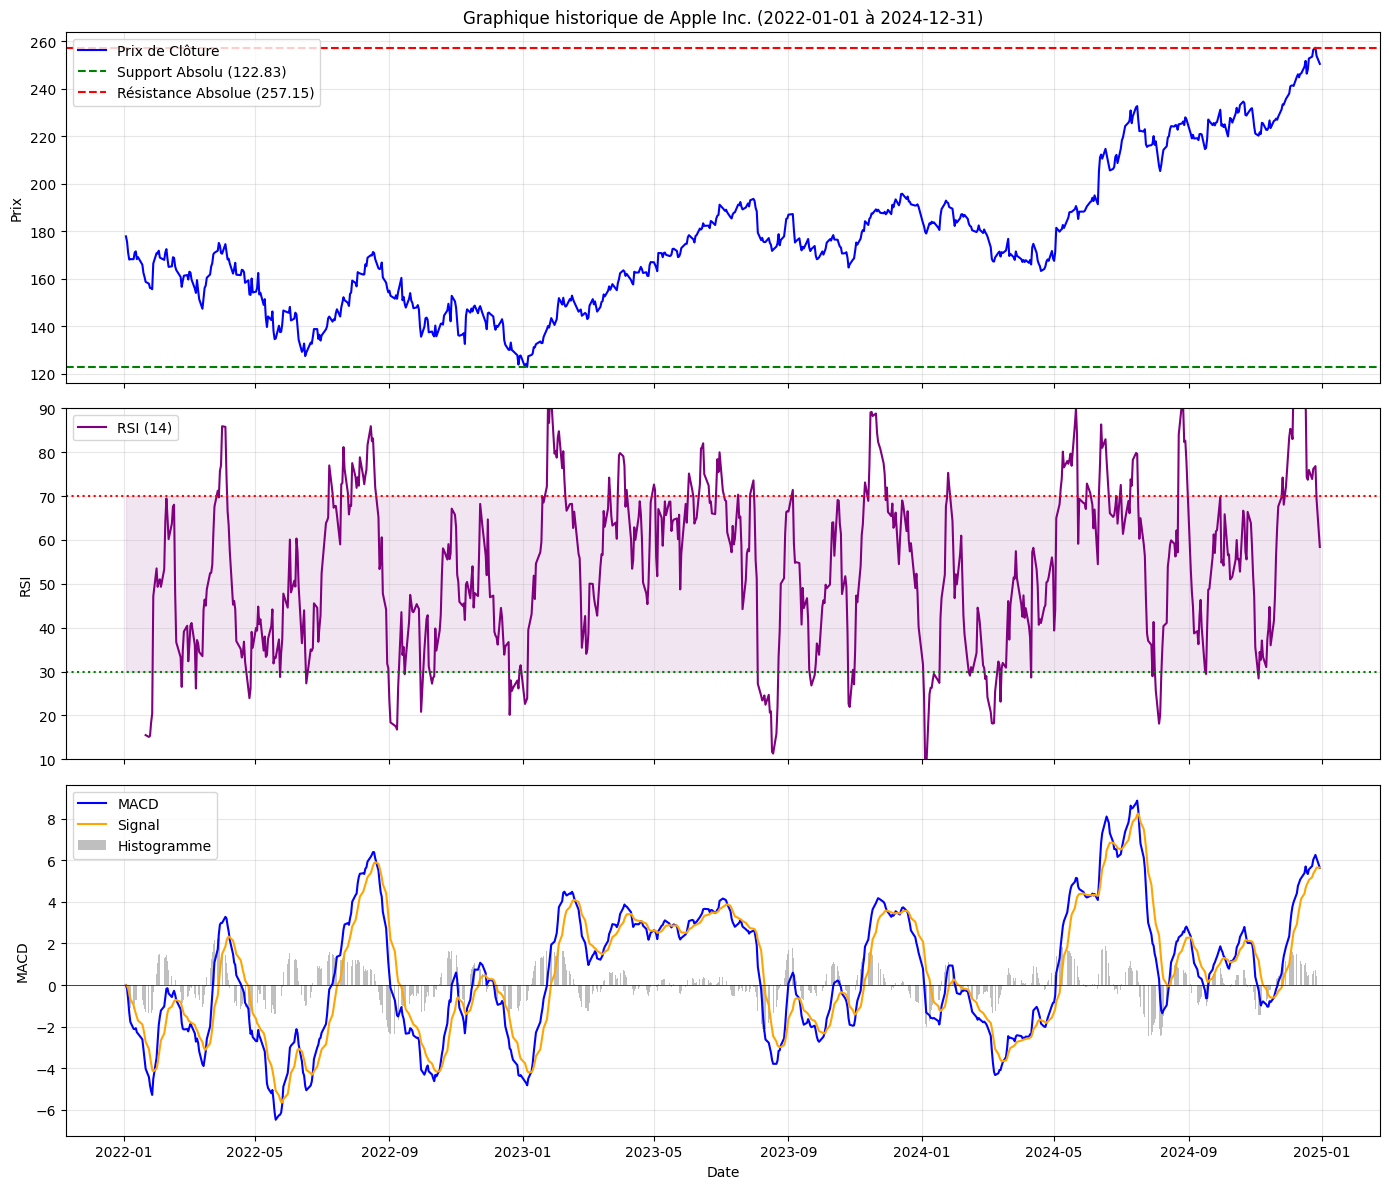

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# Demande à l'utilisateur de saisir les dates de début et de fin
date_debut = input("Entrez la date de début (format AAAA-MM-JJ, ex: 2020-01-01) : ").strip() or "2020-01-01"
date_fin = input("Entrez la date de fin (format AAAA-MM-JJ, ex: 2024-12-31) : ").strip() or "2024-12-31"

# 1. Récupération des données historiques selon les dates saisies
hist = ticker.history(start=date_debut, end=date_fin)

# 2. Calcul des indicateurs techniques
# RSI (Relative Strength Index)
delta = hist['Close'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
rs = gain / loss
hist['RSI'] = 100 - (100 / (1 + rs))

# MACD
exp1 = hist['Close'].ewm(span=12, adjust=False).mean()
exp2 = hist['Close'].ewm(span=26, adjust=False).mean()
hist['MACD'] = exp1 - exp2
hist['Signal'] = hist['MACD'].ewm(span=9, adjust=False).mean()

# Estimation simplifiée des supports et résistances sur la période récente
support = hist['Close'].min()
resistance = hist['Close'].max()

# 3. Tracé des graphiques
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# Graphique des Prix
ax1.plot(hist.index, hist['Close'], label='Prix de Clôture', color='blue')
ax1.axhline(y=support, color='green', linestyle='--', label=f'Support Absolu ({support:.2f})')
ax1.axhline(y=resistance, color='red', linestyle='--', label=f'Résistance Absolue ({resistance:.2f})')
ax1.set_title(f"Graphique historique de {nom} ({date_debut} à {date_fin})")
ax1.set_ylabel("Prix")
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

# Graphique RSI
ax2.plot(hist.index, hist['RSI'], color='purple', label='RSI (14)')
ax2.axhline(y=70, color='red', linestyle=':')
ax2.axhline(y=30, color='green', linestyle=':')
ax2.fill_between(hist.index, 30, 70, color='purple', alpha=0.1)
ax2.set_ylabel("RSI")
ax2.set_ylim(10, 90)
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)

# Graphique MACD
ax3.plot(hist.index, hist['MACD'], color='blue', label='MACD')
ax3.plot(hist.index, hist['Signal'], color='orange', label='Signal')
ax3.bar(hist.index, hist['MACD'] - hist['Signal'], color='gray', alpha=0.5, label='Histogramme')
ax3.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax3.set_ylabel("MACD")
ax3.set_xlabel("Date")
ax3.legend(loc='upper left')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
# Extraction des derniers indicateurs calculés
last_rsi = hist['RSI'].iloc[-1]
last_macd = hist['MACD'].iloc[-1]
last_signal = hist['Signal'].iloc[-1]
tendance_macd = "Haussière" if last_macd > last_signal else "Baissière"

# Interprétation RSI
if last_rsi > 70:
    interpretation_rsi = "Surachat (Extrême / Risque de correction)"
elif last_rsi < 30:
    interpretation_rsi = "Survente (Extrême / Opportunité potentielle)"
else:
    interpretation_rsi = "Neutre"

# Synthèse Technique
data_technique = [
    {"Indicateur": "Tendance Générale", "Valeur": f"Prix actuel : {format_montant(cours)}", "Interprétation": "Position historique moyen/long terme"},
    {"Indicateur": "Supports clés", "Valeur": f"{support:.2f} {devise}", "Interprétation": f"Plus bas niveau atteint sur la période ({date_debut} à {date_fin})"},
    {"Indicateur": "Résistances clés", "Valeur": f"{resistance:.2f} {devise}", "Interprétation": f"Plus haut niveau atteint sur la période ({date_debut} à {date_fin})"},
    {"Indicateur": "RSI (14 jours)", "Valeur": f"{last_rsi:.2f}", "Interprétation": interpretation_rsi},
    {"Indicateur": "MACD", "Valeur": f"{last_macd:.2f} (Signal: {last_signal:.2f})", "Interprétation": f"Tendance {tendance_macd}"}
]

df_technique = pd.DataFrame(data_technique)
display(df_technique)

,Indicateur,Valeur,Interprétation
0,Tendance Générale,Prix actuel : 348.91 USD,Position historique moyen/long terme
1,Supports clés,122.83 USD,Plus bas niveau atteint sur la période (2022-0...
2,Résistances clés,257.15 USD,Plus haut niveau atteint sur la période (2022-...
3,RSI (14 jours),58.38,Neutre
4,MACD,5.63 (Signal: 5.65),Tendance Baissière


Entrez le ticker de l'action (ex: AAPL, TSLA, MSFT): AAPL

🔍 Analyse de l'action AAPL...

=== Analyse Technique ===
Tendance: Hausse
Supports: ['264.60', '242.76', '245.07']
Résistances: ['287.84', '280.15', '317.13']
RSI (dernière valeur): 66.46 (Neutre)
Signal MACD: Vente

=== Analyse Fondamentale ===
Ticker: AAPL

--- Bilan ---
Total Assets: 359,241,000,000.00
Total Liabilities: 285,508,000,000.00
Equity: 73,733,000,000.00
Debt: 98,657,000,000.00
Cash: 54,697,000,000.00
Debt/Equity: 1.34

--- Compte de résultat ---
Revenue: 416,161,000,000.00
Net Income: 112,010,000,000.00
EPS: 7.46
Growth (YoY Revenue): 0.16

--- Flux de trésorerie ---
Operating Cash Flow: 111,482,000,000.00
Free Cash Flow: 98,767,000,000.00

--- Ratios ---
PER: 40.01
PEG: 2.76
P/B: 47.41
Dividend Yield: 0.31
ROE (%): 151.91

📌 Décision finale: ⚠️ SIGNAUX CONTRADICTOIRES (Analyser plus en détail)


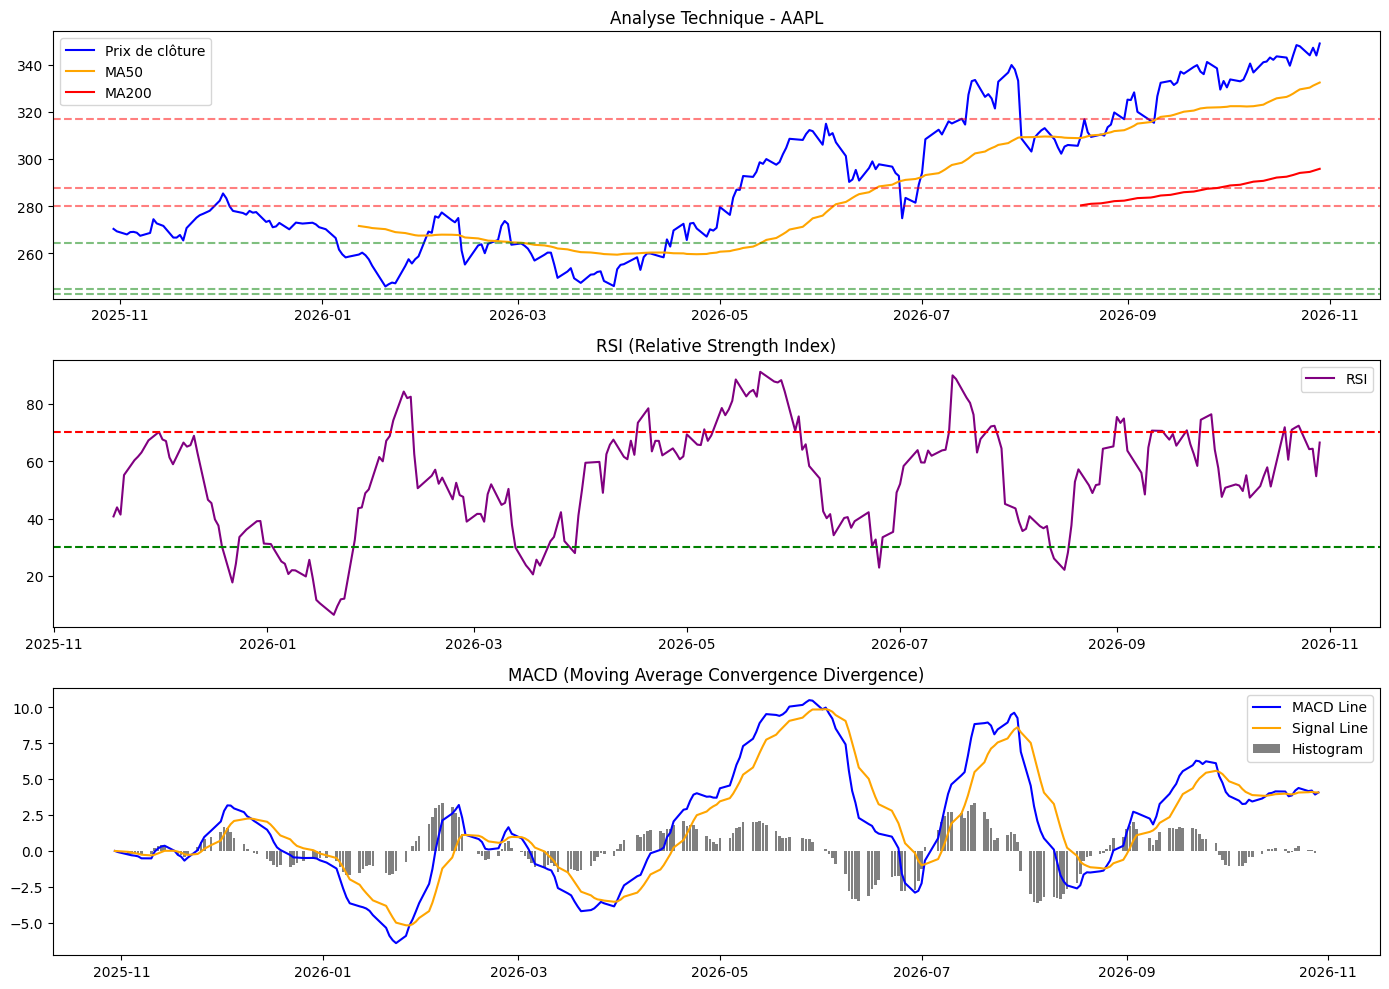

In [16]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import argrelextrema
from datetime import datetime, timedelta

# =============================================
# 1. Récupération des données boursières
# =============================================
def get_stock_data(ticker, period="1y"):
    """
    Récupère les données historiques d'une action via Yahoo Finance.
    """
    stock = yf.Ticker(ticker)
    df = stock.history(period=period)
    return df

# =============================================
# 2. Analyse Technique
# =============================================
def detect_trend(df):
    """
    Détecte la tendance globale (haussière, baissière, latérale).
    """
    # Calcul des moyennes mobiles
    df['MA50'] = df['Close'].rolling(window=50).mean()
    df['MA200'] = df['Close'].rolling(window=200).mean()

    # Détection de la tendance
    last_ma50 = df['MA50'].iloc[-1]
    last_ma200 = df['MA200'].iloc[-1]
    last_close = df['Close'].iloc[-1]

    if last_close > last_ma50 > last_ma200:
        return "Hausse"
    elif last_close < last_ma50 < last_ma200:
        return "Baisse"
    else:
        return "Latérale"

def find_support_resistance(df, window=20):
    """
    Trouve les niveaux de support et résistance en utilisant les extrema locaux.
    """
    # Trouver les maxima et minima locaux
    max_idx = argrelextrema(df['High'].values, np.greater, order=window)[0]
    min_idx = argrelextrema(df['Low'].values, np.less, order=window)[0]

    # Filtrer les niveaux significatifs (fréquents)
    support_levels = df['Low'].iloc[min_idx].value_counts().head(3).index.tolist()
    resistance_levels = df['High'].iloc[max_idx].value_counts().head(3).index.tolist()

    return support_levels, resistance_levels

def calculate_rsi(df, window=14):
    """
    Calcule le RSI (Relative Strength Index).
    """
    delta = df['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

def calculate_macd(df, fast=12, slow=26, signal=9):
    """
    Calcule le MACD (Moving Average Convergence Divergence).
    """
    ema_fast = df['Close'].ewm(span=fast, adjust=False).mean()
    ema_slow = df['Close'].ewm(span=slow, adjust=False).mean()
    macd_line = ema_fast - ema_slow
    signal_line = macd_line.ewm(span=signal, adjust=False).mean()
    histogram = macd_line - signal_line
    return macd_line, signal_line, histogram

def plot_technical_analysis(df, ticker):
    """
    Affiche le graphique avec les indicateurs techniques.
    """
    plt.figure(figsize=(14, 10))

    # Graphique des prix
    plt.subplot(3, 1, 1)
    plt.plot(df['Close'], label='Prix de clôture', color='blue')
    plt.plot(df['MA50'], label='MA50', color='orange')
    plt.plot(df['MA200'], label='MA200', color='red')
    plt.title(f"Analyse Technique - {ticker}")
    plt.legend()

    # Ajouter supports et résistances
    support, resistance = find_support_resistance(df)
    for level in support:
        plt.axhline(level, color='green', linestyle='--', alpha=0.5)
    for level in resistance:
        plt.axhline(level, color='red', linestyle='--', alpha=0.5)

    # RSI
    plt.subplot(3, 1, 2)
    rsi = calculate_rsi(df)
    plt.plot(rsi, label='RSI', color='purple')
    plt.axhline(70, color='red', linestyle='--')
    plt.axhline(30, color='green', linestyle='--')
    plt.title("RSI (Relative Strength Index)")
    plt.legend()

    # MACD
    plt.subplot(3, 1, 3)
    macd_line, signal_line, histogram = calculate_macd(df)
    plt.plot(macd_line, label='MACD Line', color='blue')
    plt.plot(signal_line, label='Signal Line', color='orange')
    plt.bar(df.index, histogram, label='Histogram', color='gray')
    plt.title("MACD (Moving Average Convergence Divergence)")
    plt.legend()

    plt.tight_layout()
    plt.show()

# =============================================
# 3. Analyse Fondamentale
# =============================================
def get_val(df, keys_to_try, default=0.0):
    """
    Récupère en toute sécurité la valeur d'une clé dans un DataFrame yfinance,
    avec gestion des clés alternatives et des erreurs.
    """
    if df is None or df.empty:
        return default
    for key in keys_to_try:
        if key in df.index:
            val = df.loc[key].iloc[0]
            if pd.notna(val):
                return float(val)
    return default

def get_fundamental_data(ticker):
    """
    Récupère les données financières de l'entreprise.
    """
    stock = yf.Ticker(ticker)

    # Récupération des différents états financiers
    balance_sheet = stock.balance_sheet
    income_statement = stock.income_stmt
    cash_flow = stock.cashflow

    # Bilan avec alternatives robustes pour parer aux changements d'index de yfinance
    total_assets = get_val(balance_sheet, ['Total Assets', 'TotalAssets'])
    total_liabilities = get_val(balance_sheet, ['Total Liabilities Net Minority Interest', 'Total Liab', 'TotalLiabilities'])
    equity = get_val(balance_sheet, ['Stockholders Equity', 'Total Stockholders Equity', 'StockholdersEquity'])
    debt = get_val(balance_sheet, ['Total Debt', 'Long Term Debt', 'TotalDebt'])
    cash = get_val(balance_sheet, ['Cash Cash Equivalents And Short Term Investments', 'Cash', 'CashAndCashEquivalents'])

    # Compte de résultat
    revenue = get_val(income_statement, ['Total Revenue', 'Operating Revenue', 'Revenue'])
    net_income = get_val(income_statement, ['Net Income', 'NetIncome'])
    eps = get_val(income_statement, ['Diluted EPS', 'Basic EPS', 'Earnings Per Share'])

    # Flux de trésorerie
    operating_cash_flow = get_val(cash_flow, ['Operating Cash Flow', 'Cash Flow From Operating Activities'])
    free_cash_flow = get_val(cash_flow, ['Free Cash Flow', 'FreeCashFlow'])

    # Ratios
    pe_ratio = stock.info.get('trailingPE', None)
    peg_ratio = stock.info.get('pegRatio', None)
    pb_ratio = stock.info.get('priceToBook', None)
    dividend_yield = stock.info.get('dividendYield', None)
    roe = (net_income / equity) * 100 if equity != 0 else None

    return {
        "Ticker": ticker,
        "Bilan": {
            "Total Assets": total_assets,
            "Total Liabilities": total_liabilities,
            "Equity": equity,
            "Debt": debt,
            "Cash": cash,
            "Debt/Equity": debt / equity if equity != 0 else None,
        },
        "Compte de résultat": {
            "Revenue": revenue,
            "Net Income": net_income,
            "EPS": eps,
            "Growth (YoY Revenue)": stock.info.get('revenueGrowth', None),
        },
        "Flux de trésorerie": {
            "Operating Cash Flow": operating_cash_flow,
            "Free Cash Flow": free_cash_flow,
        },
        "Ratios": {
            "PER": pe_ratio,
            "PEG": peg_ratio,
            "P/B": pb_ratio,
            "Dividend Yield": dividend_yield,
            "ROE (%)": roe,
        }
    }

def print_fundamental_analysis(fund_data):
    """
    Affiche les données financières de manière lisible.
    """
    print("\n=== Analyse Fondamentale ===")
    print(f"Ticker: {fund_data['Ticker']}")

    print("\n--- Bilan ---")
    for key, value in fund_data["Bilan"].items():
        print(f"{key}: {value:,.2f}" if isinstance(value, (int, float)) else f"{key}: {value}")

    print("\n--- Compte de résultat ---")
    for key, value in fund_data["Compte de résultat"].items():
        print(f"{key}: {value:,.2f}" if isinstance(value, (int, float)) else f"{key}: {value}")

    print("\n--- Flux de trésorerie ---")
    for key, value in fund_data["Flux de trésorerie"].items():
        print(f"{key}: {value:,.2f}" if isinstance(value, (int, float)) else f"{key}: {value}")

    print("\n--- Ratios ---")
    for key, value in fund_data["Ratios"].items():
        print(f"{key}: {value:.2f}" if isinstance(value, (int, float)) else f"{key}: {value}")

# =============================================
# 4. Prise de décision
# =============================================
def make_decision(technical_signal, fundamental_signal):
    """
    Prend une décision d'achat/vente/attente en fonction des signaux.
    """
    if technical_signal == "Hausse" and fundamental_signal == "Acheter":
        return "🟢 ACHETER (Tendance haussière + fondamentaux solides)"
    elif technical_signal == "Baisse" and fundamental_signal == "Vendre":
        return "🔴 VENDRE (Tendance baissière + fondamentaux faibles)"
    elif technical_signal == "Latérale" and fundamental_signal == "Attendre":
        return "⚪ ATTENDRE (Marché incertain + fondamentaux moyens)"
    else:
        return "⚠️ SIGNAUX CONTRADICTOIRES (Analyser plus en détail)"

def evaluate_fundamentals(fund_data):
    """
    Évalue les fondamentaux et donne un signal (Acheter/Vendre/Attendre).
    """
    ratios = fund_data["Ratios"]
    pe = ratios.get("PER", None)
    roe = ratios.get("ROE (%)", None)
    dividend_yield = ratios.get("Dividend Yield", None)
    revenue_growth = fund_data["Compte de résultat"].get("Growth (YoY Revenue)", None)

    # Critères pour "Acheter"
    buy_conditions = [
        (pe is not None and pe < 15),
        (roe is not None and roe > 15),
        (dividend_yield is not None and dividend_yield > 0.03),
        (revenue_growth is not None and revenue_growth > 0.05),
    ]

    # Critères pour "Vendre"
    sell_conditions = [
        (pe is not None and pe > 30),
        (roe is not None and roe < 10),
        (dividend_yield is not None and dividend_yield < 0.01),
        (revenue_growth is not None and revenue_growth < 0),
    ]

    if all(buy_conditions):
        return "Acheter"
    elif any(sell_conditions):
        return "Vendre"
    else:
        return "Attendre"

# =============================================
# 5. Fonction principale
# =============================================
def analyze_stock(ticker):
    """
    Fonction principale pour analyser une action.
    """
    print(f"\n🔍 Analyse de l'action {ticker}...")

    # 1. Récupération des données
    df = get_stock_data(ticker)
    if df.empty:
        print("❌ Impossible de récupérer les données. Vérifiez le ticker.")
        return

    # 2. Analyse technique
    trend = detect_trend(df)
    support, resistance = find_support_resistance(df)
    rsi = calculate_rsi(df).iloc[-1]
    macd_line, signal_line, _ = calculate_macd(df)
    last_macd_signal = "Achat" if macd_line.iloc[-1] > signal_line.iloc[-1] else "Vente"

    print("\n=== Analyse Technique ===")
    print(f"Tendance: {trend}")
    print(f"Supports: {[f'{s:.2f}' for s in support]}")
    print(f"Résistances: {[f'{r:.2f}' for r in resistance]}")
    print(f"RSI (dernière valeur): {rsi:.2f} ({'Suracheté' if rsi > 70 else 'Survendu' if rsi < 30 else 'Neutre'})")
    print(f"Signal MACD: {last_macd_signal}")

    # 3. Analyse fondamentale
    fund_data = get_fundamental_data(ticker)
    print_fundamental_analysis(fund_data)
    fundamental_signal = evaluate_fundamentals(fund_data)

    # 4. Prise de décision
    decision = make_decision(trend, fundamental_signal)
    print(f"\n📌 Décision finale: {decision}")

    # 5. Affichage des graphiques
    plot_technical_analysis(df, ticker)

# =============================================
# Exécution
# =============================================
if __name__ == "__main__":
    ticker = input("Entrez le ticker de l'action (ex: AAPL, TSLA, MSFT): ").upper()
    analyze_stock(ticker)